In [8]:
# Cell 1 (Settings)
import os, copy, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

warnings.filterwarnings("ignore")
from google.colab import drive
drive.mount("/content/drive")

DRIVE = "/content/drive/MyDrive/cdss_data"
PROC  = f"{DRIVE}/processed/ptbxl"
RES   = f"{DRIVE}/results/cvd"
MODEL_DIR = f"{DRIVE}/processed/models/cvd"
for d in [RES, MODEL_DIR]:
    os.makedirs(d, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cpu":
    print("WARNING: no GPU found. Training will be very slow. Runtime > Change runtime type > T4 GPU.")

# Multi-seed evaluation for final report (mean ± std)
SEEDS    = [42, 43, 44]
EPOCHS   = 25
BATCH    = 64
LR       = 1e-3
PATIENCE = 6

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda


In [9]:
# Cell 2 (Load subset + train imputation defaults)
d = np.load(f"{PROC}/ptbxl_subset_100hz.npz", allow_pickle=True)
X, Y = d["X"], d["Y"]
age, sex, split, ecg_id = d["age"], d["sex"], d["split"], d["ecg_id"]
age_median = float(d["age_median"]) if "age_median" in d.files else float(np.median(age[split == "train"]))
sex_mode   = float(d["sex_mode"]) if "sex_mode" in d.files else 0.0
CLASSES = [str(c) for c in d["classes"]]

tr = np.where(split == "train")[0]
va = np.where(split == "val")[0]
te = np.where(split == "test")[0]
print("X:", X.shape, "| train/val/test:", len(tr), len(va), len(te))
print("classes:", CLASSES)

X: (7500, 1000, 12) | train/val/test: 5000 1000 1500
classes: ['NORM', 'MI', 'STTC', 'CD', 'HYP']


In [10]:
mean = X[tr].mean(axis=(0, 1), keepdims=True)          # one value per lead
std  = X[tr].std(axis=(0, 1), keepdims=True) + 1e-6
Xn = ((X - mean) / std).transpose(0, 2, 1).astype(np.float32)   # (N, 12 leads, 1000 samples)
meta = np.stack([age / 100.0, sex], axis=1).astype(np.float32)  # (N, 2)

Xt = torch.tensor(Xn, device=device)
Mt = torch.tensor(meta, device=device)
Yt = torch.tensor(Y, device=device)
print("tensor shapes:", tuple(Xt.shape), tuple(Mt.shape), tuple(Yt.shape))

tensor shapes: (7500, 12, 1000) (7500, 2) (7500, 5)


In [11]:
# [helpers-model]
import copy, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (roc_auc_score, f1_score, precision_score,
                             recall_score, accuracy_score, brier_score_loss)
from sklearn.linear_model import LogisticRegression


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


class Block(nn.Module):
    def __init__(self, cin, cout, k=7, stride=1):
        super().__init__()
        self.conv1 = nn.Conv1d(cin, cout, k, stride=stride, padding=k // 2, bias=False)
        self.bn1 = nn.BatchNorm1d(cout)
        self.conv2 = nn.Conv1d(cout, cout, k, padding=k // 2, bias=False)
        self.bn2 = nn.BatchNorm1d(cout)
        self.short = (nn.Sequential(nn.Conv1d(cin, cout, 1, stride=stride, bias=False), nn.BatchNorm1d(cout))
                      if (cin != cout or stride != 1) else nn.Identity())
        self.act = nn.ReLU()

    def forward(self, x):
        o = self.act(self.bn1(self.conv1(x)))
        o = self.bn2(self.conv2(o))
        return self.act(o + self.short(x))


class ECGNet(nn.Module):
    """Small 1D residual CNN. n_meta > 0 joins patient info to the ECG features before the head."""
    def __init__(self, n_classes=5, n_meta=0, width=32, drop=0.3):
        super().__init__()
        self.n_meta = n_meta
        self.stem = nn.Sequential(nn.Conv1d(12, width, 15, padding=7, bias=False),
                                  nn.BatchNorm1d(width), nn.ReLU())
        self.layers = nn.Sequential(Block(width, width),
                                    Block(width, width * 2, stride=2),
                                    Block(width * 2, width * 4, stride=2),
                                    Block(width * 4, width * 8, stride=2))
        feat = width * 8 * 2
        if n_meta:
            self.meta = nn.Sequential(nn.Linear(n_meta, 16), nn.ReLU())
            feat += 16
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(feat, 64), nn.ReLU(),
                                  nn.Dropout(drop), nn.Linear(64, n_classes))

    def forward(self, x, m=None):
        h = self.layers(self.stem(x))
        h = torch.cat([h.mean(-1), h.amax(-1)], dim=1)
        if self.n_meta:
            h = torch.cat([h, self.meta(m)], dim=1)
        return self.head(h)


def safe_auc(y, p):
    return roc_auc_score(y, p) if 0 < y.sum() < len(y) else np.nan


def macro_auc(Yn, P):
    return float(np.nanmean([safe_auc(Yn[:, j], P[:, j]) for j in range(Yn.shape[1])]))


@torch.no_grad()
def predict_logits(model, Xt, Mt, idx, bs=256):
    model.eval()
    idx = torch.as_tensor(idx, device=Xt.device)
    out = []
    for i in range(0, len(idx), bs):
        b = idx[i:i + bs]
        out.append(model(Xt[b], Mt[b] if model.n_meta else None).cpu().numpy())
    return np.concatenate(out)


def predict(model, Xt, Mt, idx, bs=256):
    logits = predict_logits(model, Xt, Mt, idx, bs=bs)
    return 1.0 / (1.0 + np.exp(-np.clip(logits, -30.0, 30.0)))


def calibrate_per_class(Yv, Lv, Lt):
    """Platt scaling on validation logits per class to remove pos_weight probability inflation."""
    Pv_cal = np.zeros_like(Lv, dtype=np.float32)
    Pt_cal = np.zeros_like(Lt, dtype=np.float32)
    cal_params = []
    for j in range(Yv.shape[1]):
        if 0 < Yv[:, j].sum() < len(Yv):
            lr = LogisticRegression(C=1e6, solver="lbfgs")
            lr.fit(Lv[:, [j]], Yv[:, j])
            Pv_cal[:, j] = lr.predict_proba(Lv[:, [j]])[:, 1]
            Pt_cal[:, j] = lr.predict_proba(Lt[:, [j]])[:, 1]
            cal_params.append({"coef": float(lr.coef_[0, 0]), "intercept": float(lr.intercept_[0])})
        else:
            Pv_cal[:, j] = 1.0 / (1.0 + np.exp(-Lv[:, j]))
            Pt_cal[:, j] = 1.0 / (1.0 + np.exp(-Lt[:, j]))
            cal_params.append({"coef": 1.0, "intercept": 0.0})
    return Pv_cal, Pt_cal, cal_params


def train_model(use_meta, Xt, Mt, Yt, tr, va, seed, epochs=25, bs=64, lr=1e-3, patience=6):
    set_seed(seed)
    dev = Xt.device
    n_classes = Yt.shape[1]
    model = ECGNet(n_classes=n_classes, n_meta=Mt.shape[1] if use_meta else 0).to(dev)

    pos = Yt[torch.as_tensor(tr, device=dev)].float().mean(0).clamp(min=1e-3, max=1 - 1e-3)
    pos_weight = ((1 - pos) / pos).clamp(1.0, 5.0)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)

    tr_t = torch.as_tensor(tr, device=dev)
    Yva = Yt[torch.as_tensor(va, device=dev)].cpu().numpy()
    best_auc, best_state, bad = -1.0, None, 0
    hist = {"train_loss": [], "val_auc": []}

    for ep in range(epochs):
        model.train()
        perm = tr_t[torch.randperm(len(tr_t), device=dev)]
        total = 0.0
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            if len(b) < 2:
                continue
            opt.zero_grad()
            logits = model(Xt[b], Mt[b] if use_meta else None)
            loss = loss_fn(logits, Yt[b])
            loss.backward()
            opt.step()
            total += loss.item() * len(b)
        val_auc = macro_auc(Yva, predict(model, Xt, Mt, va))
        sched.step(val_auc if not np.isnan(val_auc) else 0.0)
        hist["train_loss"].append(total / len(tr_t))
        hist["val_auc"].append(val_auc)
        print(f"  epoch {ep + 1:2d} | train loss {hist['train_loss'][-1]:.4f} | val macro AUROC {val_auc:.4f}")
        if val_auc > best_auc:
            best_auc, best_state, bad = val_auc, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                print("  early stop")
                break
    model.load_state_dict(best_state)
    return model, hist, best_auc


def tune_thresholds(Yv, Pv):
    ths = []
    for j in range(Yv.shape[1]):
        best_t, best_f = 0.5, -1.0
        for t in np.linspace(0.05, 0.95, 91):
            f = f1_score(Yv[:, j], (Pv[:, j] >= t).astype(int), zero_division=0)
            if f > best_f:
                best_f, best_t = f, t
        ths.append(best_t)
    return np.array(ths)


def per_class_metrics(Yn, P, ths, classes):
    rows = []
    for j, c in enumerate(classes):
        pred = (P[:, j] >= ths[j]).astype(int)
        rows.append({"class": c,
                     "auroc": safe_auc(Yn[:, j], P[:, j]),
                     "f1": f1_score(Yn[:, j], pred, zero_division=0),
                     "precision": precision_score(Yn[:, j], pred, zero_division=0),
                     "recall": recall_score(Yn[:, j], pred, zero_division=0),
                     "accuracy": accuracy_score(Yn[:, j], pred),
                     "brier": brier_score_loss(Yn[:, j], P[:, j])})
    return pd.DataFrame(rows)


def metadata_baseline(meta, Yn, tr, va, te):
    """Logistic regression on age and sex only. Returns validation and test probabilities."""
    Pv = np.zeros((len(va), Yn.shape[1])); Pt = np.zeros((len(te), Yn.shape[1]))
    for j in range(Yn.shape[1]):
        lr = LogisticRegression(max_iter=1000, class_weight="balanced").fit(meta[tr], Yn[tr, j])
        Pv[:, j] = lr.predict_proba(meta[va])[:, 1]
        Pt[:, j] = lr.predict_proba(meta[te])[:, 1]
    return Pv, Pt

In [12]:
# Section 4: Train, Calibrate on Val, Evaluate on Test, and Save Self-Contained Bundle
Yn = Y.astype(int)
MODELS = ["Metadata only (age, sex)", "ECG only (CNN)", "ECG + age + sex (CNN)"]
rows, histories, test_preds = [], {}, {}

for seed in SEEDS:
    print(f"\n===== seed {seed} =====")

    # 1) metadata only
    Pv, Pt = metadata_baseline(meta, Yn, tr, va, te)
    ths = tune_thresholds(Yn[va], Pv)
    m = per_class_metrics(Yn[te], Pt, ths, CLASSES); m["model"] = MODELS[0]; m["seed"] = seed
    rows.append(m); test_preds[f"meta_seed{seed}"] = Pt

    # 2) ECG only, 3) ECG + metadata
    for name, use_meta, tag in [(MODELS[1], False, "ecg"), (MODELS[2], True, "ecg_meta")]:
        print(f"\n{name}")
        model, hist, best = train_model(use_meta, Xt, Mt, Yt, tr, va, seed,
                                        epochs=EPOCHS, bs=BATCH, lr=LR, patience=PATIENCE)
        Lv = predict_logits(model, Xt, Mt, va)
        Lt = predict_logits(model, Xt, Mt, te)
        Pv_raw = 1.0 / (1.0 + np.exp(-np.clip(Lv, -30.0, 30.0)))
        Pt_raw = 1.0 / (1.0 + np.exp(-np.clip(Lt, -30.0, 30.0)))

        # Calibrate probabilities on validation logits
        Pv_cal, Pt_cal, cal_params = calibrate_per_class(Yn[va], Lv, Lt)
        raw_brier = np.mean([brier_score_loss(Yn[te, j], Pt_raw[:, j]) for j in range(len(CLASSES))])
        cal_brier = np.mean([brier_score_loss(Yn[te, j], Pt_cal[:, j]) for j in range(len(CLASSES))])
        print(f"  Test Macro Brier: raw = {raw_brier:.4f} -> calibrated = {cal_brier:.4f}")

        ths = tune_thresholds(Yn[va], Pv_cal)
        m = per_class_metrics(Yn[te], Pt_cal, ths, CLASSES); m["model"] = name; m["seed"] = seed
        rows.append(m)
        histories[(name, seed)] = hist
        test_preds[f"{tag}_seed{seed}"] = Pt_cal
        test_preds[f"{tag}_raw_seed{seed}"] = Pt_raw

        # Save self-contained inference bundle (weights + scaler stats + calibrators + thresholds)
        torch.save({
            "state_dict": model.state_dict(),
            "n_classes": len(CLASSES),
            "n_meta": Mt.shape[1] if use_meta else 0,
            "classes": CLASSES,
            "signal_mean": mean.squeeze(0),      # (1, 12)
            "signal_std": std.squeeze(0),        # (1, 12)
            "age_median": age_median,
            "sex_mode": sex_mode,
            "cal_params": cal_params,
            "thresholds": ths,
        }, f"{MODEL_DIR}/{tag}_seed{seed}.pt")

results = pd.concat(rows, ignore_index=True)
results.to_csv(f"{RES}/02_baseline_results_per_class.csv", index=False)
np.savez(f"{RES}/02_test_predictions.npz", ecg_id=ecg_id[te], Y_test=Yn[te],
         classes=np.array(CLASSES), **test_preds)
print("\nsaved calibrated results, test predictions, and self-contained model bundles")


===== seed 42 =====

ECG only (CNN)
  epoch  1 | train loss 0.7790 | val macro AUROC 0.8751
  epoch  2 | train loss 0.6475 | val macro AUROC 0.8908
  epoch  3 | train loss 0.6069 | val macro AUROC 0.8987
  epoch  4 | train loss 0.5898 | val macro AUROC 0.9073
  epoch  5 | train loss 0.5621 | val macro AUROC 0.9084
  epoch  6 | train loss 0.5508 | val macro AUROC 0.9046
  epoch  7 | train loss 0.5407 | val macro AUROC 0.9058
  epoch  8 | train loss 0.5238 | val macro AUROC 0.9162
  epoch  9 | train loss 0.5222 | val macro AUROC 0.9096
  epoch 10 | train loss 0.5154 | val macro AUROC 0.9124
  epoch 11 | train loss 0.4849 | val macro AUROC 0.9090
  epoch 12 | train loss 0.4666 | val macro AUROC 0.9168
  epoch 13 | train loss 0.4320 | val macro AUROC 0.9217
  epoch 14 | train loss 0.4207 | val macro AUROC 0.9198
  epoch 15 | train loss 0.4084 | val macro AUROC 0.9184
  epoch 16 | train loss 0.3897 | val macro AUROC 0.9174
  epoch 17 | train loss 0.3628 | val macro AUROC 0.9196
  epoch 18 

In [13]:
# Section 5: Summary Table (including Brier score across 3 seeds)
METRICS = ["auroc", "f1", "precision", "recall", "accuracy", "brier"]


def fmt(g):
    m, s = g.mean(), g.std()
    return f"{m:.3f}" if (len(g) < 2 or np.isnan(s)) else f"{m:.3f} ± {s:.3f}"


macro_seed = results.groupby(["model", "seed"])[METRICS].mean().reset_index()
summary = macro_seed.groupby("model")[METRICS].agg(fmt).loc[MODELS]
display(summary)
summary.to_csv(f"{RES}/02_baseline_summary_macro.csv")

auc_tab = results.pivot_table(index="class", columns="model", values="auroc", aggfunc="mean")[MODELS].loc[CLASSES]
display(auc_tab.round(3))
auc_tab.to_csv(f"{RES}/02_baseline_auroc_per_class.csv")

,auroc,f1,precision,recall,accuracy,brier
model,,,,,,
"Metadata only (age, sex)",0.684 ± 0.000,0.455 ± 0.000,0.359 ± 0.000,0.673 ± 0.000,0.617 ± 0.000,0.229 ± 0.000
ECG only (CNN),0.912 ± 0.001,0.729 ± 0.004,0.708 ± 0.003,0.755 ± 0.010,0.869 ± 0.002,0.090 ± 0.001
ECG + age + sex (CNN),0.913 ± 0.001,0.724 ± 0.003,0.714 ± 0.007,0.743 ± 0.008,0.870 ± 0.001,0.090 ± 0.001


model,"Metadata only (age, sex)",ECG only (CNN),ECG + age + sex (CNN)
class,,,
NORM,0.759,0.932,0.934
MI,0.689,0.897,0.900
STTC,0.688,0.921,0.923
CD,0.638,0.907,0.904
HYP,0.646,0.903,0.905


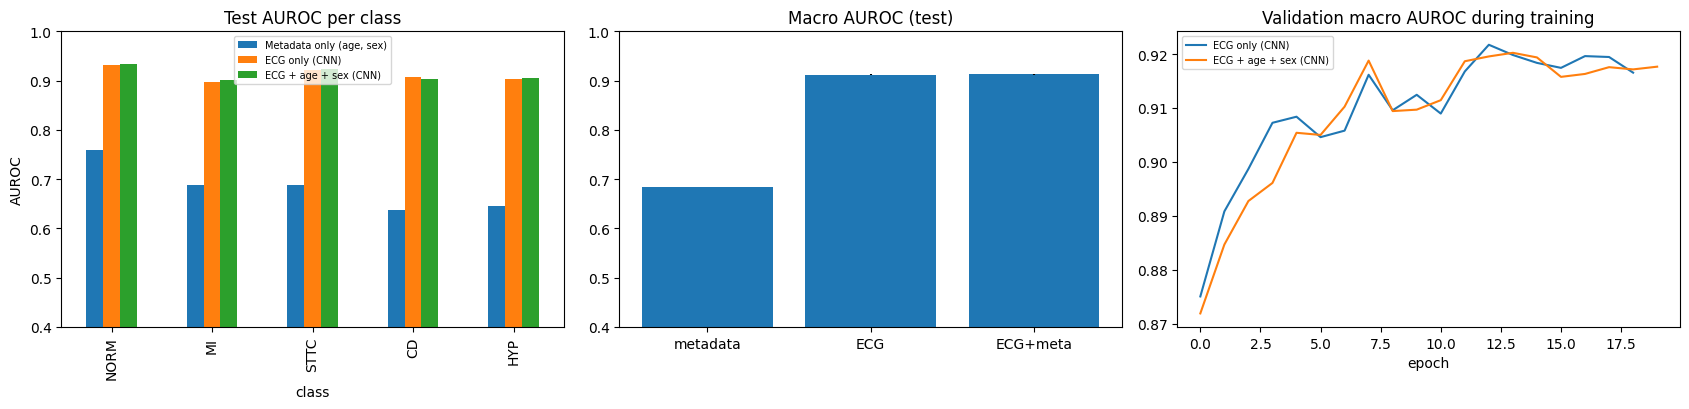

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))

auc_tab.plot.bar(ax=ax[0]); ax[0].set_title("Test AUROC per class"); ax[0].set_ylabel("AUROC")
ax[0].set_ylim(0.4, 1.0); ax[0].legend(fontsize=7)

vals = macro_seed.groupby("model")["auroc"].mean().loc[MODELS]
errs = macro_seed.groupby("model")["auroc"].std().fillna(0).loc[MODELS]
ax[1].bar(range(3), vals.values, yerr=errs.values)
ax[1].set_xticks(range(3)); ax[1].set_xticklabels(["metadata", "ECG", "ECG+meta"])
ax[1].set_ylim(0.4, 1.0); ax[1].set_title("Macro AUROC (test)")

for (name, seed), h in histories.items():
    if seed == SEEDS[0]:
        ax[2].plot(h["val_auc"], label=name)
ax[2].set_title("Validation macro AUROC during training"); ax[2].set_xlabel("epoch"); ax[2].legend(fontsize=7)

plt.tight_layout()
plt.savefig(f"{RES}/02_baseline_results.png", dpi=150)
plt.show()